# 05 - Are Flood Claims Paid More Slowly After Mega-Storms?

**DSC 411/511 Semester Project** · Venkat Repaka, Ritik Gaire

**Question:** When a very big storm creates tens of thousands of claims at the same time, do people wait longer for their money?

We measure the **payment time** = days from the date the claim was **opened** (`openDate`) to the date of the **last payment**
(`mostRecentPaymentDate`). Both dates are in the FEMA file, so we do not need any new data.

**Plan**
1. Prepare the data and check the payment time
2. Which storms were paid fastest and slowest?
3. Is a bigger storm a slower storm?
4. Inside one storm: who waits longest?
5. What explains the payment time? (a model)
6. Our answer

## 1. Prepare the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
SEED = 42

df = pd.read_parquet('data/claims_clean.parquet')
raw = pd.read_parquet('/Users/home/workspace/School/DataMining/project/NfipClaimsV3.parquet',
                      columns=['id', 'openDate', 'mostRecentPaymentDate', 'asOfDate'])
for c in ['openDate', 'mostRecentPaymentDate']:
    raw[c] = pd.to_datetime(raw[c].astype(str), errors='coerce')
df = df.merge(raw, on='id', how='left')
print('Data snapshot date (asOfDate):', raw['asOfDate'].max().date())

# Storm size = how many claims the same named storm produced (all claims, paid or not)
df['event'] = df['floodEvent'].fillna('no named event')
event_size = df.loc[df['floodEvent'].notna(), 'floodEvent'].value_counts()
df['storm_size'] = df['floodEvent'].map(event_size)

paid = df[df['amountPaidOnBuildingClaim'] > 0].copy()
paid['payment_days'] = (paid['mostRecentPaymentDate'] - paid['openDate']).dt.days
print(f'Paid building claims: {len(paid):,}')
print(paid['payment_days'].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(0))

Data snapshot date (asOfDate): 2026-09-08
Paid building claims: 212,932
count    212932.0
mean        135.0
std         178.0
min        -502.0
25%          43.0
50%          76.0
75%         143.0
90%         318.0
99%         939.0
max        2302.0
Name: payment_days, dtype: float64


**Two problems we have to handle before we compare anything.**

1. **Noise:** a payment cannot happen before the claim was opened. Negative payment times are wrong, so we set them to missing.
2. **Claims that are not finished yet.** The data is a snapshot from September 2026. A claim from a 2025 flood has had little time,
   so it can only have a *short* payment time so far; slow 2025 claims are simply not paid yet. If we kept 2025, recent storms would look
   faster than they are. So we only compare floods from **2020 to 2024** (every claim had at least about 20 months).

We also note that `mostRecentPaymentDate` is the **last** payment. If a claim got a first payment quickly and an extra payment later,
we measure until the extra payment. So our number is "time until the claim was fully paid", not "time until the first money".

Because a few claims take years, the **mean** is pulled up a lot. We use the **median** and the **share paid within 90 days**,
which are not affected by the very long cases.

Negative payment times (noise): 12
           claims  median  within_90_days
loss_year                                
2020        24004    44.0            0.80
2021        34724    54.0            0.75
2022        44742   100.0            0.46
2023        16267    57.0            0.72
2024        82726   101.0            0.44
2025        10457    56.0            0.73

Claims we compare (floods 2020-2024): 202,463


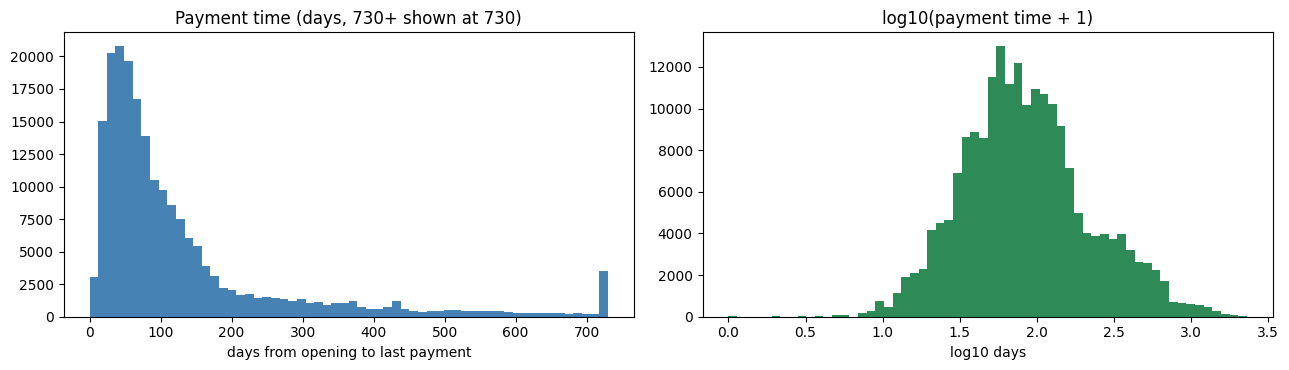

In [2]:
print('Negative payment times (noise):', int((paid['payment_days'] < 0).sum()))
paid.loc[paid['payment_days'] < 0, 'payment_days'] = np.nan
paid = paid[paid['payment_days'].notna()]

by_year = paid.groupby('loss_year')['payment_days'].agg(claims='size', median='median',
                                                         within_90_days=lambda s: (s <= 90).mean())
print(by_year.round(2))
paid = paid[paid['loss_year'] <= 2024].copy()
paid['within_90'] = (paid['payment_days'] <= 90).astype(int)
print(f'\nClaims we compare (floods 2020-2024): {len(paid):,}')

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(paid['payment_days'].clip(upper=730), bins=60, color='steelblue')
ax[0].set_title('Payment time (days, 730+ shown at 730)'); ax[0].set_xlabel('days from opening to last payment')
ax[1].hist(np.log10(paid['payment_days'] + 1), bins=60, color='seagreen')
ax[1].set_title('log10(payment time + 1)'); ax[1].set_xlabel('log10 days')
plt.tight_layout(); plt.show()

**What we see**
- Only **12** claims had a payment before the claim was opened (noise). We removed them.
- Half of all paid claims were fully paid within **76 days**, but 10% took more than **318 days**, and a few took several years.
  The histogram has a long tail to the right, so the median is a better summary than the mean (135 days).
- **2022 and 2024 are much slower** than the other years: a median of about 100 days, and only 44-46% of claims paid within 90 days,
  against 72-80% in 2020, 2021 and 2023. These are the years of Hurricane Ian (2022) and Hurricanes Helene and Milton (2024).
- 2025 looks fast (56 days), but this is the problem we described: slow 2025 claims are not finished yet. That is why we left 2025 out.
  We compare **202,463** paid claims from floods in 2020-2024.

## 2. Which storms were paid fastest and slowest?

We look at the named storms with at least 500 paid claims, plus the claims with no named storm.

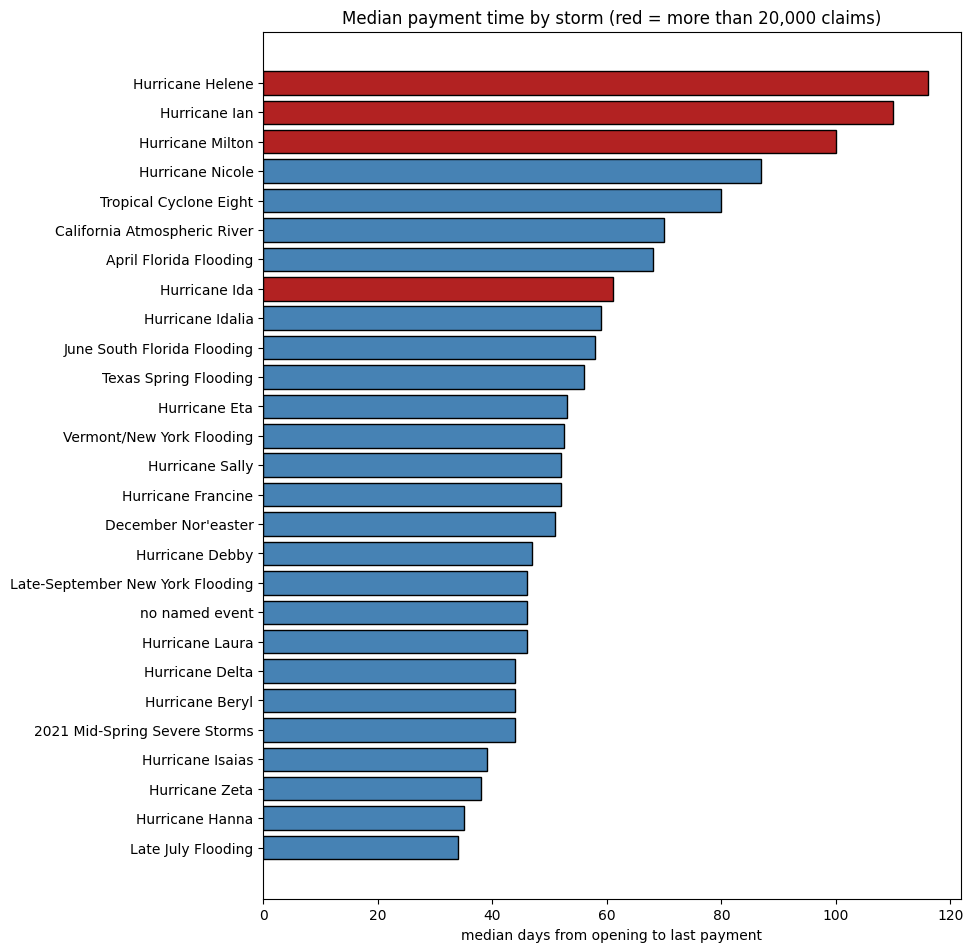

,paid_claims,all_claims,median_days,within_90_days,p90_days,loss_year
event,,,,,,
Hurricane Helene,50433,58018,116.0,0.35,368.0,2024.0
Hurricane Ian,37087,48634,110.0,0.40,500.0,2022.0
Hurricane Milton,16250,21594,100.0,0.43,304.0,2024.0
Hurricane Nicole,1172,1625,87.0,0.52,291.0,2022.0
Tropical Cyclone Eight,642,738,80.0,0.56,228.8,2024.0
California Atmospheric River,1322,1964,70.0,0.63,243.0,2023.0
April Florida Flooding,3002,3440,68.0,0.64,315.0,2023.0
Hurricane Ida,21649,28273,61.0,0.71,218.0,2021.0
Hurricane Idalia,4775,5520,59.0,0.71,223.6,2023.0


In [3]:
storms = paid.groupby('event').agg(paid_claims=('id', 'size'), all_claims=('storm_size', 'first'),
                                   median_days=('payment_days', 'median'), within_90_days=('within_90', 'mean'),
                                   p90_days=('payment_days', lambda s: s.quantile(0.9)),
                                   loss_year=('loss_year', 'median'))
storms = storms[storms['paid_claims'] >= 500].sort_values('median_days', ascending=False)
storms['all_claims'] = storms['all_claims'].fillna(0).astype(int)

plt.figure(figsize=(9, 0.38 * len(storms) + 1))
colors = ['firebrick' if n >= 20000 else 'steelblue' for n in storms['all_claims']]
plt.barh(storms.index, storms['median_days'], color=colors, edgecolor='black')
plt.gca().invert_yaxis(); plt.xlabel('median days from opening to last payment')
plt.title('Median payment time by storm (red = more than 20,000 claims)'); plt.show()
storms.round(2)

**What we see.** The three slowest storms are the three biggest Florida hurricanes: **Helene** (median 116 days), **Ian** (110) and
**Milton** (100). Only 35-43% of their claims were paid within 90 days. Ian is the slowest at the end of the line: 10% of its claims
took more than **500 days**.

Most other storms and the claims without a named storm were paid in **35 to 60 days**, with 70-80% paid within 90 days.

**One big exception: Hurricane Ida** (2021). It had more than 28,000 claims, but its median was only **61 days** and 71% were paid
within 90 days, almost as fast as a small storm. So "big" alone does not always mean "slow".

## 3. Is a bigger storm a slower storm?

Every named storm is one point: its size (number of claims) and its median payment time. Storm size goes from a few hundred
to more than 50,000 claims, so we put it on a **log scale**. We also compute the **correlation** between log storm size and the
median payment time, using storms with at least 100 paid claims.

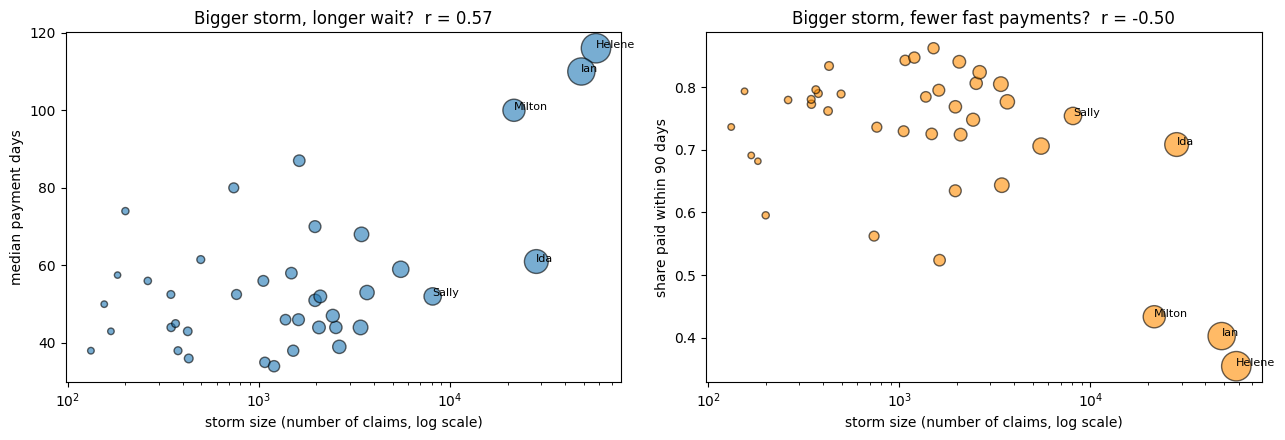

Named storms with at least 100 paid claims: 39
Correlation, log storm size vs median days        : 0.57
Correlation, log storm size vs share within 90 days: -0.50


In [4]:
pts = paid[paid['floodEvent'].notna()].groupby('event').agg(paid_claims=('id', 'size'), size=('storm_size', 'first'),
                                                             median_days=('payment_days', 'median'),
                                                             within_90=('within_90', 'mean'))
pts = pts[pts['paid_claims'] >= 100]
r_days = np.corrcoef(np.log10(pts['size']), pts['median_days'])[0, 1]
r_90 = np.corrcoef(np.log10(pts['size']), pts['within_90'])[0, 1]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(pts['size'], pts['median_days'], s=np.sqrt(pts['paid_claims']) * 2, alpha=0.6, edgecolor='black')
ax[1].scatter(pts['size'], pts['within_90'], s=np.sqrt(pts['paid_claims']) * 2, alpha=0.6, edgecolor='black', color='darkorange')
for name in pts.nlargest(5, 'size').index:
    ax[0].annotate(name.replace('Hurricane ', ''), (pts.loc[name, 'size'], pts.loc[name, 'median_days']), fontsize=8)
    ax[1].annotate(name.replace('Hurricane ', ''), (pts.loc[name, 'size'], pts.loc[name, 'within_90']), fontsize=8)
for a in ax: a.set_xscale('log'); a.set_xlabel('storm size (number of claims, log scale)')
ax[0].set_ylabel('median payment days'); ax[0].set_title(f'Bigger storm, longer wait?  r = {r_days:.2f}')
ax[1].set_ylabel('share paid within 90 days'); ax[1].set_title(f'Bigger storm, fewer fast payments?  r = {r_90:.2f}')
plt.tight_layout(); plt.show()
print(f'Named storms with at least 100 paid claims: {len(pts)}')
print(f'Correlation, log storm size vs median days        : {r_days:.2f}')
print(f'Correlation, log storm size vs share within 90 days: {r_90:.2f}')

In [5]:
bins = [0, 1000, 5000, 20000, 1e9]
labels = ['under 1,000 claims', '1,000-5,000', '5,000-20,000', 'over 20,000']
paid['storm_group'] = pd.cut(paid['storm_size'], bins=bins, labels=labels).astype(str)
paid.loc[paid['floodEvent'].isna(), 'storm_group'] = 'no named storm'
order = ['no named storm'] + labels
groups = paid.groupby('storm_group').agg(claims=('id', 'size'), storms=('event', 'nunique'),
                                         median_days=('payment_days', 'median'), within_90_days=('within_90', 'mean')).reindex(order)
groups.round(2)

,claims,storms,median_days,within_90_days
storm_group,,,,
no named storm,32482,1,46.0,0.78
"under 1,000 claims",4692,31,53.0,0.73
"1,000-5,000",28972,18,50.0,0.76
"5,000-20,000",10898,2,55.0,0.73
"over 20,000",125419,4,102.0,0.44


**What we see**
- There is a clear link: **bigger storms are paid more slowly** (correlation **0.57** between log storm size and median days), and
  fewer of their claims are paid within 90 days (correlation **-0.50**).
- But the link is **not a smooth line**. Storms with under 1,000, 1,000-5,000 and 5,000-20,000 claims are all paid in about the same
  time (median **50-55 days**, about 75% within 90 days), the same as claims without a named storm (46 days).
  Only the storms with **more than 20,000 claims** are much slower: median **102 days**, and only **44%** within 90 days.
- So it looks like a **capacity limit**: the system works normally up to a certain size, and above it the waiting time doubles.
  We only have four storms above 20,000 claims (Helene, Ian, Milton, Ida), so we cannot say exactly where the limit is.

## 4. Inside one storm: who waits longest?

A big storm could be slow because it has **more large and complicated claims**, not only because there are many claims.
So we look **inside** the three biggest storms: are large claims slower than small claims, and is one state slower than another?

In [6]:
big3 = ['Hurricane Helene', 'Hurricane Ian', 'Hurricane Ida']
inside = paid[paid['event'].isin(big3)].copy()
inside['payment_size'] = pd.qcut(inside['amountPaidOnBuildingClaim'], 4, labels=['smallest 25%', 'second 25%', 'third 25%', 'largest 25%'])
t = inside.pivot_table(index='payment_size', columns='event', values='payment_days', aggfunc='median', observed=True)
print('Median payment days by payment size, inside each storm:')
print(t.round(0))
print()
st = inside.groupby(['event', 'state']).agg(claims=('id', 'size'), median_days=('payment_days', 'median'),
                                             within_90_days=('within_90', 'mean'))
st = st[st['claims'] >= 300]
print('Median payment days by state, inside each storm (states with 300+ claims):')
st.round(2)

Median payment days by payment size, inside each storm:
event         Hurricane Helene  Hurricane Ian  Hurricane Ida
payment_size                                                
smallest 25%              78.0           73.0           48.0
second 25%               111.0          102.0           63.0
third 25%                119.0          113.0           80.0
largest 25%              143.0          161.0          114.0

Median payment days by state, inside each storm (states with 300+ claims):


claims  median_days  within_90_days
event            state                                     
Hurricane Helene FL      47672        117.0            0.35
                 GA        508        101.0            0.44
                 NC       1685        125.0            0.29
Hurricane Ian    FL      36016        111.0            0.40
                 SC        937         89.0            0.50
Hurricane Ida    CT        589         64.0            0.72
                 LA       9955         61.0            0.70
                 MS        325         43.0            0.86
                 NJ       6150         60.0            0.72
                 NY       2806         63.0            0.71
                 PA       1552         65.5            0.67

**What we see**
- **Bigger claims take longer, in every storm.** In Ian, the smallest 25% of payments took a median of 73 days and the largest 25% took
  **161 days**. Helene goes from 78 to 143 days, Ida from 48 to 114. Large claims need more inspection and often extra payments later.
- **But the storm matters too.** Even the *smallest* claims of Helene and Ian (73-78 days) waited longer than the *median* claim of an
  ordinary storm (about 50 days). So the mega-storms are not slow only because they have bigger claims.
- **The state matters less than the storm.** Ida was paid in about the same time in Louisiana, New Jersey, New York, Connecticut and
  Pennsylvania (60-65 days). In Helene, Florida (117 days) and North Carolina (125) were both slow.
  In Ian, South Carolina (89 days) was faster than Florida (111), but it had only 937 claims.

## 5. What explains the payment time? (a model)

Now we put everything into one model. The target is **log(payment days + 1)**, because the days are very skewed.
The features describe the **storm** (size, named or not, loss year, month), the **place** (state group), the **building**
(zone, foundation, occupancy) and the **claim** (payment amount, coverage). Here the payment amount is allowed: we do not want to
*predict* at the start, we want to *explain* which things go together with a long wait.

We use a random forest (on a 60,000-claim sample) and **permutation importance** on a separate test part: how much the R² drops
when one feature is shuffled.

R2 on the test part (log days): 0.289


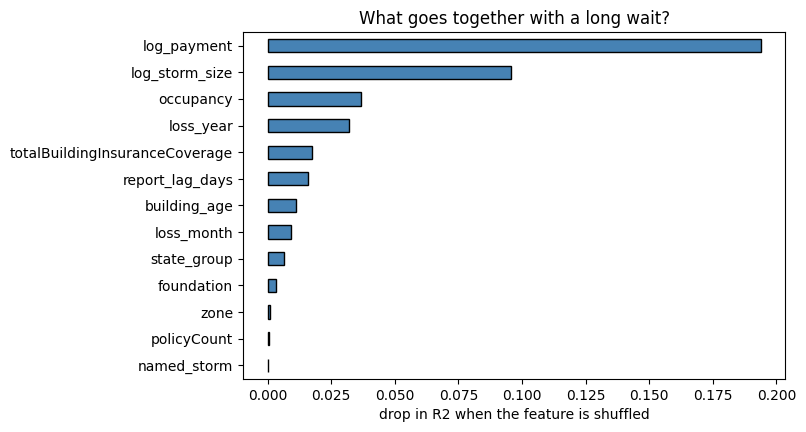

log_payment                       0.194
log_storm_size                    0.096
occupancy                         0.037
loss_year                         0.032
totalBuildingInsuranceCoverage    0.018
report_lag_days                   0.016
building_age                      0.011
loss_month                        0.009
state_group                       0.006
foundation                        0.003
zone                              0.001
policyCount                       0.001
named_storm                      -0.000
dtype: float64

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score

top_states = paid['state'].value_counts().head(10).index
paid['state_group'] = paid['state'].where(paid['state'].isin(top_states), 'other')
paid['log_storm_size'] = np.log10(paid['storm_size'].fillna(1))
paid['log_payment'] = np.log10(paid['amountPaidOnBuildingClaim'])
NUM = ['log_storm_size', 'named_storm', 'loss_year', 'loss_month', 'log_payment', 'totalBuildingInsuranceCoverage',
       'policyCount', 'building_age', 'report_lag_days']
CAT = ['state_group', 'zone', 'foundation', 'occupancy']
X = pd.get_dummies(paid[NUM + CAT], columns=CAT, dtype=int)
y = np.log1p(paid['payment_days'])

s = X.sample(60000, random_state=SEED).index
Xa, Xb, ya, yb = train_test_split(X.loc[s], y.loc[s], test_size=0.3, random_state=SEED)
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=SEED).fit(Xa, ya)
print(f'R2 on the test part (log days): {r2_score(yb, rf.predict(Xb)):.3f}')

# Shuffle each original feature (all its one-hot columns together)
base = r2_score(yb, rf.predict(Xb))
rng = np.random.default_rng(SEED)
drops = {}
for f in NUM + CAT:
    cols = [c for c in X.columns if c == f or c.startswith(f + '_')]
    Xp = Xb.copy()
    Xp[cols] = Xb[cols].values[rng.permutation(len(Xb))]
    drops[f] = base - r2_score(yb, rf.predict(Xp))
drops = pd.Series(drops).sort_values()
drops.plot.barh(color='steelblue', edgecolor='black', figsize=(7, 4.5))
plt.xlabel('drop in R2 when the feature is shuffled'); plt.title('What goes together with a long wait?'); plt.show()
drops.sort_values(ascending=False).round(3)

**What we see**
- The model explains **29%** of the differences in payment time (R² 0.289 on log days). Waiting time has many reasons that are not
  in the data (disputes, missing documents, contractors), so this is not a surprise.
- The two most important features are the **size of the payment** (R² drops by 0.19 when it is shuffled) and the **size of the storm**
  (0.10). Then come the occupancy (condo buildings and businesses take longer) and the loss year.
- The **flood zone and the foundation hardly matter** (0.001-0.003), and the **state** matters little (0.006) once the storm size is known.
- One caution: permutation importance can be smaller for features that are related to other features (for example state and storm size,
  because the big storms were all in Florida). So "state does not matter" should be read as "state adds little after storm size".

## 6. Our answer

| | Median days to last payment | Paid within 90 days |
|---|---|---|
| Claims with no named storm | 46 | 78% |
| Storms with under 20,000 claims | 50-55 | 73-76% |
| **Storms with over 20,000 claims** | **102** | **44%** |
| Hurricane Helene / Ian / Milton | 116 / 110 / 100 | 35% / 40% / 43% |
| Hurricane Ida (the exception) | 61 | 71% |

> **Yes.** Claims from the mega-storms were paid about **twice as slowly**: a median of about 100-116 days for Helene, Ian and Milton,
> against about 50 days for ordinary storms, and fewer than half of their claims were paid within 90 days. The slowdown appears only
> above about 20,000 claims, which looks like a capacity limit. Inside a storm, large claims wait the longest, but even the smallest
> claims of the mega-storms waited longer than a typical claim of a normal storm. Hurricane Ida shows that a big storm does not have to
> be slow: with more than 28,000 claims, it was paid in 61 days.

**Limits**
- We measure the time to the **last** payment, so extra payments made months later count as "slow".
- The three slow storms were all **Florida** hurricanes, and Ida's claims were spread over several states. With only four mega-storms we
  cannot fully separate "a very big storm" from "a very big storm in Florida".
- We only see claims that were **paid**. Claims closed without payment, and 2025 claims that are still open, are not in the comparison.

**Why it matters:** people wait for this money to repair their homes. If the waiting time doubles after a mega-storm, FEMA and the
insurance companies need more adjusters ready before the big storms, especially in Florida.